# setup

In [33]:
library(tidyverse)
library(tximport)
library(DESeq2)
library(rtracklayer)
library(limma)
library(RColorBrewer)
library(gridExtra)
library(ggrastr)
library(msigdbr)
library(fgsea)
library(org.Hs.eg.db)
library(AnnotationDbi)
library(patchwork)
library(pheatmap)
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))
sessionInfo()

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] pheatmap_1.0.12             patchwork_1.3.0            
 [3] org.Hs.eg.db_3.16.0         AnnotationDbi_1.60.2       
 [5] fgsea_1.24.0                msigdbr_7.5.1              
 [7] ggrastr_1.0.2               gridExtra_2.3              
 [9] RColorBrewer_1.1-3          lim

# load sample metadata

In [13]:
metadata <- read.delim("./rsem_metadata.tsv", sep='\t')

rsem_files <- metadata$filename

metadata$group <- paste0(metadata$condition, "_", metadata$timepoint)
head(metadata)

,sample_id,condition,timepoint,replicate,stimulus,bafinh,original_condition_label,source_replicate,source_batch,source_project,filename,basename,group
,<chr>,<chr>,<chr>,<int>,<chr>,<lgl>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Veh_1h_r1,Veh,1h,1,none,FALSE,Veh,1,stim_brm014,gm12878_stim_rnaseq,/mnt/storage/home/agulka/projects/gm12878_stim_rnaseq/res/stim_brm014/T1_Veh_r1/rsem_quant/rep1/rep1_T1_Veh_r1_anno_rsem.genes.results,rep1_T1_Veh_r1_anno_rsem.genes.results,Veh_1h
2,Veh_1h_r2,Veh,1h,2,none,FALSE,Veh,2,stim_brm014,gm12878_stim_rnaseq,/mnt/storage/home/agulka/projects/gm12878_stim_rnaseq/res/stim_brm014/T1_Veh_r2/rsem_quant/rep1/rep1_T1_Veh_r2_anno_rsem.genes.results,rep1_T1_Veh_r2_anno_rsem.genes.results,Veh_1h
3,Veh_1h_r3,Veh,1h,3,none,FALSE,Veh,1,070726_GM12878_stimulus_revisions,070726_GM12878_stimulus_revisions,/mnt/storage/home/agulka/projects/070726_GM12878_stimulus_revisions/res/Veh_1h/rsem_quant/rep1/rep1_Veh_1h_anno_rsem.genes.results,rep1_Veh_1h_anno_rsem.genes.results,Veh_1h
4,Veh_1h_r4,Veh,1h,4,none,FALSE,Veh,2,070726_GM12878_stimulus_revisions,070726_GM12878_stimulus_revisions,/mnt/storage/home/agulka/projects/070726_GM12878_stimulus_revisions/res/Veh_1h/rsem_quant/rep2/rep2_Veh_1h_anno_rsem.genes.results,rep2_Veh_1h_anno_rsem.genes.results,Veh_1h
5,BAFinh_1h_r1,BAFinh,1h,1,none,TRUE,BRM,1,stim_brm014,gm12878_stim_rnaseq,/mnt/storage/home/agulka/projects/gm12878_stim_rnaseq/res/stim_brm014/T1_BRM_r1/rsem_quant/rep1/rep1_T1_BRM_r1_anno_rsem.genes.results,rep1_T1_BRM_r1_anno_rsem.genes.results,BAFinh_1h
6,BAFinh_1h_r2,BAFinh,1h,2,none,TRUE,BRM,2,stim_brm014,gm12878_stim_rnaseq,/mnt/storage/home/agulka/projects/gm12878_stim_rnaseq/res/stim_brm014/T1_BRM_r2/rsem_quant/rep1/rep1_T1_BRM_r2_anno_rsem.genes.results,rep1_T1_BRM_r2_anno_rsem.genes.results,BAFinh_1h


# load counts and abundances

In [14]:
txi <- tximport(rsem_files, type="rsem", txIn=F)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 
36 
37 
38 
39 
40 
41 
42 
43 
44 
45 
46 
47 
48 




# generate row metadata

In [15]:
#row metadata

gencode <- import("~/manuscripts/BAF_stimulus_CellGenomics/inputs/GENCODE/gencode.v47.annotation.gtf.gz")
gencode <- gencode[which(gencode$type=="gene")]

#generate rowdata
row.data <- data.frame(gencode@elementMetadata)
rownames(row.data) <- row.data$gene_id
row.data$gene_id <- NULL
#generate column with cleaned ENSEMBL IDs
row.data$gene_id_base <- gsub("\\..*$", "", rownames(row.data)) 
#remove NA columns
row.data <- row.data[,colSums(is.na(row.data))<nrow(row.data)]
# add genome coordinates
row.data$chr <- as.character(gencode@seqnames)
row.data$start <- as.numeric(gencode@ranges@start)
row.data$end <- row.data$start + as.numeric(gencode@ranges@width)

row.data <- row.data %>% filter(gene_type=="protein_coding")

# filter TPMs and metadata

In [16]:
#filter txi object
nrow(txi$abundance)
#first, filter to exclude non-protein coding genes using the row metadata
txi$abundance <- txi$abundance[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$abundance))),] 
txi$counts <- txi$counts[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$counts))),]
txi$length <- txi$length[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$length))),]
nrow(txi$abundance)
#next, filter to remove lowly-expressed and 0-length genes
filt <- which(apply(txi$abundance,MARGIN=1,FUN=max) <= 1 | #genes with low expression (where max TPM for all samples is <=1)
                apply(txi$length, MARGIN=1,FUN=min)==0) #genes with weird annotations (length=0)

#filter out these genes from txi object
txi$abundance <- txi$abundance[-filt,]
txi$counts <- txi$counts[-filt,]
txi$length <- txi$length[-filt,]

#get rid of any NA rows
txi$counts <- txi$counts[-which(!rowSums(is.finite(txi$abundance))),]
txi$length <- txi$length[-which(!rowSums(is.finite(txi$abundance))),]
txi$abundance <- txi$abundance[-which(!rowSums(is.finite(txi$abundance))),]
nrow(txi$abundance)
     
#filter row metadata to match rows of filtered txi object
row.data <- row.data[match(gsub("\\..*$", "", 
                                rownames(txi$abundance)), 
                           row.data$gene_id_base),]
nrow(txi$abundance)
nrow(row.data)

[1] 59526

[1] 20092

[1] 12572

[1] 12572

[1] 12572

# run differential expression

In [73]:
deg_res <- function (des, row.data, contrast) 
{
    res <- results(des, contrast = contrast)
    res <- res %>% data.frame() %>% rownames_to_column("ENSEMBL_ID") %>% 
            mutate(gene=row.data$gene_name,change = case_when(log2FoldChange > log2(1.5) & 
                                      padj < 0.05 ~ "up", 
                                      log2FoldChange < -log2(1.5) & padj < 0.05 ~ "down", 
                                      TRUE ~ "ns"))
    return(res)
}

dds <- DESeqDataSetFromTximport(txi,metadata, design=~source_batch+group)
des <- DESeq(dds)

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



# generate batch-corrected TPM matrix

In [74]:
vst_dds <- vst(dds, blind=FALSE)
assay(vst_dds) <- removeBatchEffect(assay(vst_dds), batch=vst_dds$source_batch, design=model.matrix(~condition, colData(vst_dds)))
batchCorr_abundance <- assay(vst_dds)
colnames(batchCorr_abundance) <- metadata$sample_id
head(batchCorr_abundance)

write.table(batchCorr_abundance, "VST_abundance_batchCorr.tsv", row.names=F, sep='\t')
write.table(row.data, "gene_metadata.tsv", row.names=F, sep='\t')

using 'avgTxLength' from assays(dds), correcting for library size



,Veh_1h_r1,Veh_1h_r2,Veh_1h_r3,Veh_1h_r4,BAFinh_1h_r1,BAFinh_1h_r2,BAFinh_1h_r3,BAFinh_1h_r4,IFN_1h_r1,IFN_1h_r2,⋯,Dex_6h_r3,Dex_6h_r4,BAFinh_IFN_6h_r1,BAFinh_IFN_6h_r2,BAFinh_IFN_6h_r3,BAFinh_IFN_6h_r4,BAFinh_Dex_6h_r1,BAFinh_Dex_6h_r2,BAFinh_Dex_6h_r3,BAFinh_Dex_6h_r4
ENSG00000188976.10,11.094304,11.169113,11.132622,11.134389,11.118339,11.178742,11.086892,11.187021,11.059505,11.188558,⋯,10.998416,10.958889,11.043341,11.049208,11.091930,11.081983,11.071431,11.095712,11.061275,11.036950
ENSG00000187961.13,9.014802,8.992152,8.970106,8.997438,9.046781,8.964662,8.991622,9.085525,9.158773,8.866050,⋯,9.160877,9.122619,9.305117,9.272518,9.167390,9.188384,9.274732,9.348391,9.349675,9.161636
ENSG00000188290.10,7.801568,7.899061,7.809184,7.845335,7.845141,7.823411,7.673416,7.788787,7.812653,7.858984,⋯,7.673416,7.820948,7.927304,7.842870,7.793922,7.786678,7.769325,7.877694,7.843363,7.851805
ENSG00000187608.9,10.725684,10.687047,10.837515,10.814747,10.696059,10.747423,10.593214,10.696314,10.843076,10.792432,⋯,10.298451,10.393347,11.069044,11.102103,11.095639,11.015751,9.968420,10.063241,9.903502,10.009911
ENSG00000188157.14,10.606964,10.442599,10.491575,10.581773,10.597952,10.519072,10.520757,10.708317,10.649879,10.593940,⋯,10.270505,10.090975,10.437892,10.331589,10.673126,10.545096,10.133408,10.287173,10.384406,10.380983
ENSG00000131591.17,9.144124,9.054241,9.091234,9.041870,9.157504,9.054617,9.137378,9.056220,9.067490,9.133857,⋯,9.130096,9.114730,9.453197,9.361364,9.466780,9.450670,9.379182,9.432083,9.339884,9.168810


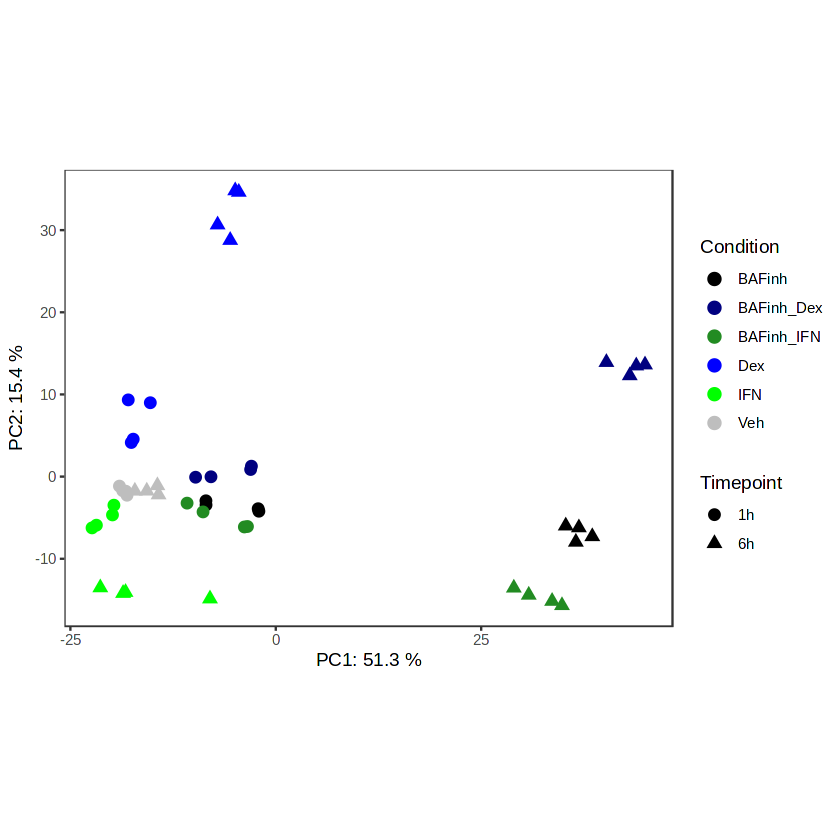

In [9]:
# PCA - all conditions

pca_top_1000 <- prcomp(t(assay(vst_dds)[order(apply(assay(vst_dds), 1, var), decreasing=TRUE),] %>% head(1000)), scale=TRUE)
var_expl <- 100*pca_top_1000$sdev^2/sum(pca_top_1000$sdev^2)
p1 <- pca_top_1000$x %>% 
    ggplot(aes(x=PC1,y=PC2)) + geom_point(aes(color=metadata$condition, shape=metadata$timepoint), size=3) + theme_bw() + coord_fixed() + theme(panel.grid=element_blank()) + 
    scale_color_manual(name="Condition", values=c("Veh"="grey", "BAFinh"="black", "IFN"="green", "Dex"="blue", "BAFinh_IFN"="forestgreen", "BAFinh_Dex"="navy")) +
    xlab(paste("PC1:", format(var_expl[1], digits=3), "%")) + ylab(paste("PC2:", format(var_expl[2], digits=3), "%")) +
    scale_shape_discrete(name="Timepoint")
p1

# write out differential expression results

In [75]:
ifn_1h <- deg_res(des, row.data, c("group", "IFN_1h", "Veh_1h"))
ifn_6h <- deg_res(des, row.data, c("group", "IFN_6h", "Veh_6h"))
dex_1h <- deg_res(des, row.data, c("group", "Dex_1h", "Veh_1h"))
dex_6h <- deg_res(des, row.data, c("group", "Dex_6h", "Veh_6h"))

bafinh_1h <- deg_res(des, row.data, c("group", "BAFinh_IFN_1h", "Veh_1h"))
bafinh_6h <- deg_res(des, row.data, c("group", "BAFinh_IFN_6h", "Veh_6h"))

bafinh_ifn_ifn_1h <- deg_res(des, row.data, c("group", "BAFinh_IFN_1h", "IFN_1h"))
bafinh_ifn_ifn_6h <- deg_res(des, row.data, c("group", "BAFinh_IFN_6h", "IFN_6h"))
bafinh_dex_dex_1h <- deg_res(des, row.data, c("group", "BAFinh_Dex_1h", "Dex_1h"))
bafinh_dex_dex_6h <- deg_res(des, row.data, c("group", "BAFinh_Dex_6h", "Dex_6h"))

In [31]:
write.table(ifn_1h, "IFN_1h_DEGs.tsv", sep='\t', row.names=F)
write.table(ifn_6h, "IFN_6h_DEGs.tsv", sep='\t', row.names=F)
write.table(dex_1h, "Dex_1h_DEGs.tsv", sep='\t', row.names=F)
write.table(dex_6h, "Dex_6h_DEGs.tsv", sep='\t', row.names=F)
write.table(bafinh_1h, "BAFinh_1h_DEGs.tsv", sep='\t', row.names=F)
write.table(bafinh_6h, "BAFinh_6h_DEGs.tsv", sep='\t', row.names=F)
write.table(bafinh_ifn_ifn_1h, "BAFinh_IFN_1h_DEGs.tsv", sep='\t', row.names=F)
write.table(bafinh_ifn_ifn_6h, "BAFinh_IFN_6h_DEGs.tsv", sep='\t', row.names=F)
write.table(bafinh_dex_dex_1h, "BAFinh_Dex_1h_DEGs.tsv", sep='\t', row.names=F)
write.table(bafinh_dex_dex_6h, "BAFinh_Dex_6h_DEGs.tsv", sep='\t', row.names=F)

# run DEG analysis for original and new batches separately

In [23]:
txi_old <- txi 
txi_old$abundance <- txi$abundance[,metadata$replicate < 3]
txi_old$counts <- txi$counts[,metadata$replicate < 3]
txi_old$length <- txi$length[,metadata$replicate < 3]

metadata_old <- metadata[metadata$replicate < 3,]
dds_old <- DESeqDataSetFromTximport(txi_old, colData=metadata_old, design=~group)
des_old <- DESeq(dds_old)

txi_new <- txi 
txi_new$abundance <- txi$abundance[,metadata$replicate > 2]
txi_new$counts <- txi$counts[,metadata$replicate > 2]
txi_new$length <- txi$length[,metadata$replicate > 2]

metadata_new <- metadata[metadata$replicate > 2,]
dds_new <- DESeqDataSetFromTximport(txi_new, colData=metadata_new, design=~group)
des_new <- DESeq(dds_new)

#stim DEGs - original n=2 reps
ifn_1h_old <- deg_res(des_old, row.data, c("group", "IFN_1h", "Veh_1h"))
ifn_6h_old <- deg_res(des_old, row.data, c("group", "IFN_6h", "Veh_6h"))
dex_1h_old <- deg_res(des_old, row.data, c("group", "Dex_1h", "Veh_1h"))
dex_6h_old <- deg_res(des_old, row.data, c("group", "Dex_6h", "Veh_6h"))

#stim DEGs - new n=2 reps
ifn_1h_new <- deg_res(des_new, row.data, c("group", "IFN_1h", "Veh_1h"))
ifn_6h_new <- deg_res(des_new, row.data, c("group", "IFN_6h", "Veh_6h"))
dex_1h_new <- deg_res(des_new, row.data, c("group", "Dex_1h", "Veh_1h"))
dex_6h_new <- deg_res(des_new, row.data, c("group", "Dex_6h", "Veh_6h"))

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [32]:
write.table(ifn_1h_old, "IFN_1h_DEGs_b1.tsv", sep='\t', row.names=F)
write.table(ifn_6h_old, "IFN_6h_DEGs_b1.tsv", sep='\t', row.names=F)
write.table(dex_1h_old, "Dex_1h_DEGs_b1.tsv", sep='\t', row.names=F)
write.table(dex_6h_old, "Dex_6h_DEGs_b1.tsv", sep='\t', row.names=F)
write.table(ifn_1h_new, "IFN_1h_DEGs_b2.tsv", sep='\t', row.names=F)
write.table(ifn_6h_new, "IFN_6h_DEGs_b2.tsv", sep='\t', row.names=F)
write.table(dex_1h_new, "Dex_1h_DEGs_b2.tsv", sep='\t', row.names=F)
write.table(dex_6h_new, "Dex_6h_DEGs_b2.tsv", sep='\t', row.names=F)

In [100]:
dds <- DESeqDataSetFromTximport(txi,metadata, design=~source_batch+group)

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport



using 'avgTxLength' from assays(dds), correcting for library size



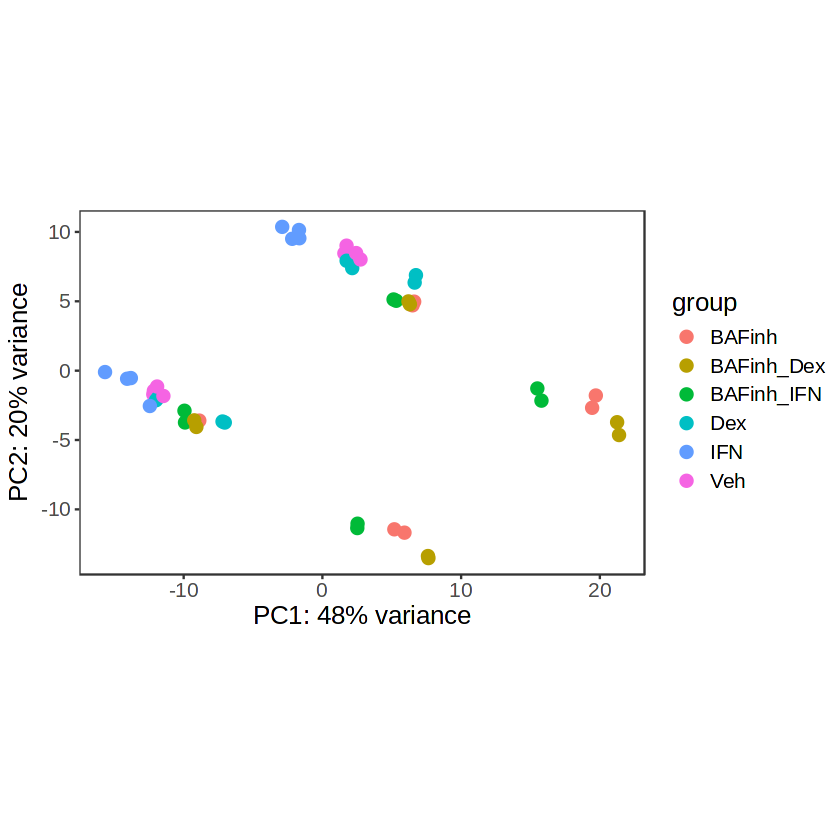

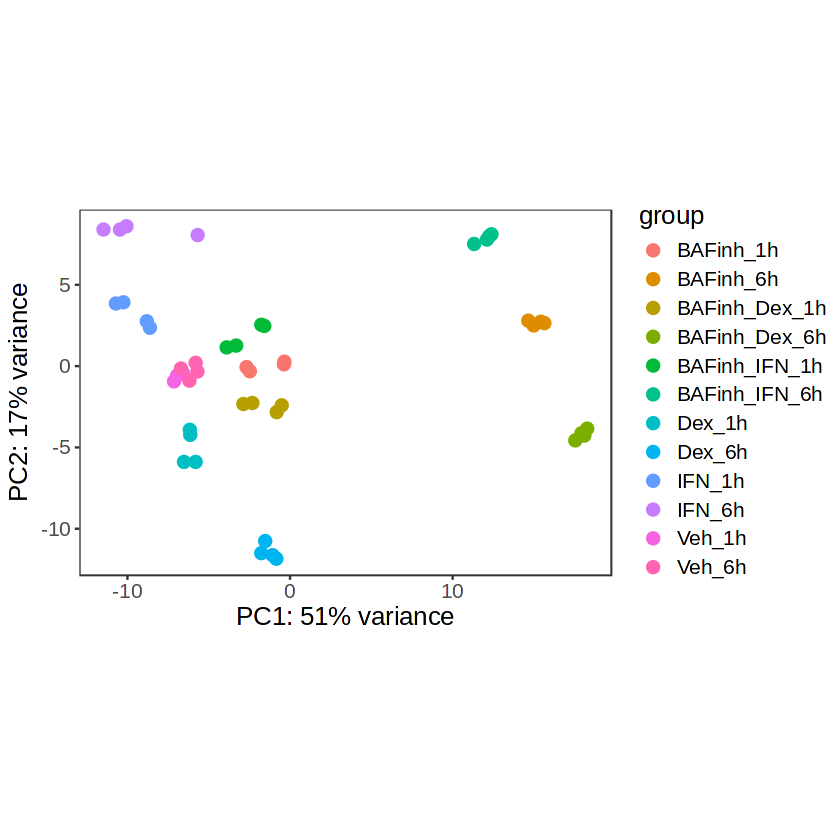

In [108]:
colData(vst_)

DataFrame with 48 rows and 13 columns
           sample_id   condition   timepoint replicate    stimulus    bafinh
         <character> <character> <character> <integer> <character> <logical>
1          Veh_1h_r1         Veh          1h         1        none     FALSE
2          Veh_1h_r2         Veh          1h         2        none     FALSE
3          Veh_1h_r3         Veh          1h         3        none     FALSE
4          Veh_1h_r4         Veh          1h         4        none     FALSE
5       BAFinh_1h_r1      BAFinh          1h         1        none      TRUE
...              ...         ...         ...       ...         ...       ...
44  BAFinh_IFN_6h_r4  BAFinh_IFN          6h         4         IFN      TRUE
45  BAFinh_Dex_6h_r1  BAFinh_Dex          6h         1         Dex      TRUE
46  BAFinh_Dex_6h_r2  BAFinh_Dex          6h         2         Dex      TRUE
47  BAFinh_Dex_6h_r3  BAFinh_Dex          6h         3         Dex      TRUE
48  BAFinh_Dex_6h_r4  BAFinh_Dex      